# CAPSTONE PROJECT
## Irregular Migration Across the Western Balkan Route, impact on Montenegro and prediction of the number of illegals by month in 2027

### Notebook 02 — Modeling and Forecasting

**Research question:** Using historical IOM DTM data, how can recorded arrivals on the Western Balkan Route (WBR), especially arrivals recorded in Montenegro, be estimated for the next 3, 6 and 12 months?

**Target variables**
1. WBR total: monthly recorded arrivals in `Other_Countries_Areas_Monthly` where `Route == 'WBR'`.
2. Montenegro WBR: monthly recorded arrivals where `Route == 'WBR'` and `ISO3 - Country of arrival == 'MNE'`.

**Interpretation:** these are recorded arrival counts/events as defined by the source, not necessarily unique individuals. This notebook uses the Q1 2026 workbook; if the last observation is March 2026, forecasts start in April 2026.


## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load the source sheet used for forecasting

In [4]:
file_path = '/content/DTM Europe_Q1_2026_Dataset.xlsx'

# This is the main sheet for the WBR monthly arrival forecast
im1_2 = pd.read_excel(
    file_path,
    sheet_name='Other_Countries_Areas_Monthly'
)

im1_2['Date'] = pd.to_datetime(im1_2['Date'], errors='coerce')
im1_2['Arrivals'] = pd.to_numeric(im1_2['Arrivals'], errors='coerce')

print('Shape:', im1_2.shape)
print('Routes:')
print(im1_2['Route'].value_counts(dropna=False))
print('Arrival countries:')
print(sorted(im1_2['ISO3 - Country of arrival'].dropna().unique()))

Shape: (1066, 7)
Routes:
Route
WBR         724
EU Other    342
Name: count, dtype: int64
Arrival countries:
['ALB', 'BIH', 'HRV', 'MKD', 'MNE', 'ROU', 'SRB', 'SVN', 'XKX']


## 3. Create monthly target series

In [5]:
ROUTE_CODE = 'WBR'
MONTENEGRO_CODE = 'MNE'

base = im1_2.dropna(subset=['Date', 'Arrivals']).copy()

# A. Total WBR arrivals across the countries represented in this sheet
df_wbr = base[base['Route'] == ROUTE_CODE].copy()
df_wbr['Month'] = df_wbr['Date'].dt.to_period('M').dt.to_timestamp()

wb_monthly = (
    df_wbr.groupby('Month')['Arrivals']
    .sum()
    .sort_index()
)

# B. WBR arrivals recorded in Montenegro only
df_mne = base[
    (base['Route'] == ROUTE_CODE) &
    (base['ISO3 - Country of arrival'] == MONTENEGRO_CODE)
].copy()
df_mne['Month'] = df_mne['Date'].dt.to_period('M').dt.to_timestamp()

mne_monthly = (
    df_mne.groupby('Month')['Arrivals']
    .sum()
    .sort_index()
)

print('WBR:', len(wb_monthly), 'months |', wb_monthly.index.min(), 'to', wb_monthly.index.max())
print('Montenegro WBR:', len(mne_monthly), 'months |', mne_monthly.index.min(), 'to', mne_monthly.index.max())

display(wb_monthly.tail())
display(mne_monthly.tail())

WBR: 123 months | 2016-01-01 00:00:00 to 2026-03-01 00:00:00
Montenegro WBR: 123 months | 2016-01-01 00:00:00 to 2026-03-01 00:00:00


,Arrivals
Month,
2025-11-01,3995
2025-12-01,2621
2026-01-01,1660
2026-02-01,2763
2026-03-01,3284


,Arrivals
Month,
2025-11-01,364
2025-12-01,257
2026-01-01,203
2026-02-01,405
2026-03-01,453


## 4. Validate monthly continuity before modeling

This check is important. A missing month must not automatically be interpreted as zero arrivals. If missing months are found, inspect the source and decide whether they mean zero recorded arrivals or unavailable data before proceeding.

In [6]:
def check_monthly_series(series, series_name):
    if series.empty:
        raise ValueError(f'{series_name} is empty. Check the route/country filters.')

    expected = pd.date_range(
        start=series.index.min(),
        end=series.index.max(),
        freq='MS'
    )
    missing_months = expected.difference(series.index)

    print(f'\\n{series_name}')
    print('Observed months:', len(series))
    print('Expected months:', len(expected))
    print('Missing months:', len(missing_months))
    if len(missing_months):
        print(missing_months)

    if series.isna().any():
        print('WARNING: series contains missing values.')

    return missing_months

missing_wbr = check_monthly_series(wb_monthly, 'Western Balkan Route')
missing_mne = check_monthly_series(mne_monthly, 'Montenegro — WBR')

\nWestern Balkan Route
Observed months: 123
Expected months: 123
Missing months: 0
\nMontenegro — WBR
Observed months: 123
Expected months: 123
Missing months: 0


## 5. Select the target series

Run the model first for the overall route, then for Montenegro. The selected series must have a continuous monthly index and enough observations for lag features and testing.

In [7]:
# Choose one target:
TARGET_NAME = 'Western Balkan Route'
target = wb_monthly.copy()

# For the Montenegro-only model, replace the two lines above with:
# TARGET_NAME = 'Montenegro — WBR'
# target = mne_monthly.copy()

# Reindex only after verifying the meaning of any missing months.
# This notebook stops rather than silently filling missing months.
if target.empty:
    raise ValueError('Target series is empty.')

expected_index = pd.date_range(target.index.min(), target.index.max(), freq='MS')
if not target.index.equals(expected_index):
    raise ValueError(
        'Target series has missing months or a non-month-start index. '
        'Investigate the source before modeling; do not automatically fill with zero.'
    )

if len(target) < 36:
    raise ValueError('Too few monthly observations for this proposed lag/test setup.')

print('Selected target:', TARGET_NAME)
print('Start:', target.index.min(), '| End:', target.index.max())
print('Observations:', len(target))

Selected target: Western Balkan Route
Start: 2016-01-01 00:00:00 | End: 2026-03-01 00:00:00
Observations: 123


## 6. Visualize the selected target

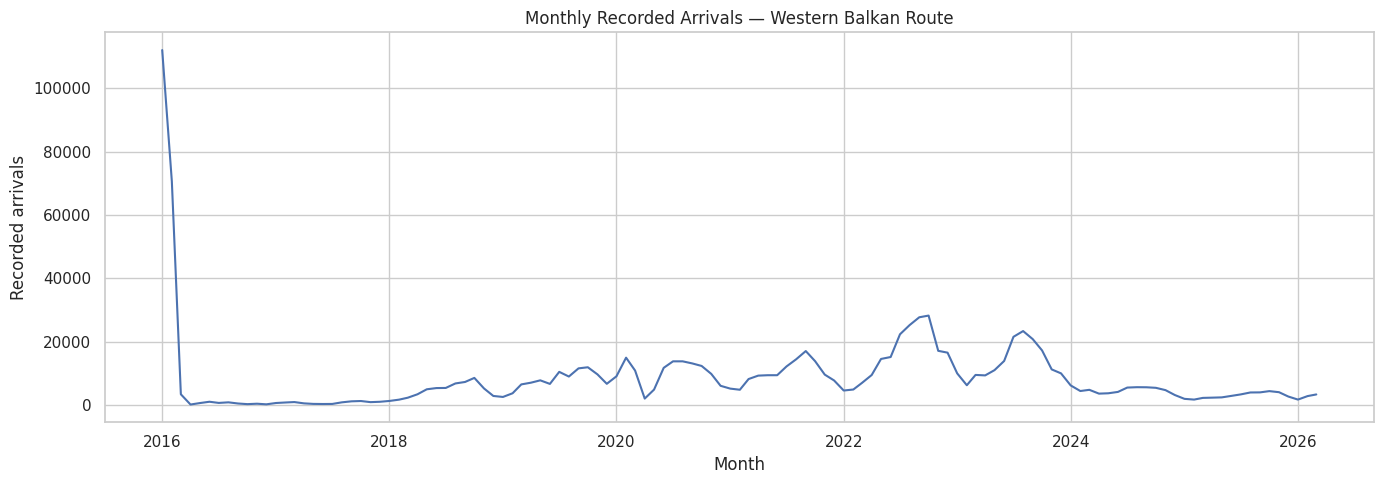

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(target.index, target.values)
plt.title(f'Monthly Recorded Arrivals — {TARGET_NAME}')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.tight_layout()
plt.show()

## 7. Feature Engineering

Create calendar, lag and rolling-average features. Lag features use only past target values. Rolling means are shifted by one month to avoid data leakage.

In [18]:
def make_features(series):
    data = pd.DataFrame({'Arrivals': series.copy()})
    data.index.name = 'Month'

    data['Time_Index'] = np.arange(len(data))
    data['Month_Number'] = data.index.month

    data['Month_Sin'] = np.sin(2 * np.pi * data['Month_Number'] / 12)
    data['Month_Cos'] = np.cos(2 * np.pi * data['Month_Number'] / 12)

    data['Lag_1'] = data['Arrivals'].shift(1)
    data['Lag_3'] = data['Arrivals'].shift(3)
    data['Lag_6'] = data['Arrivals'].shift(6)
    data['Lag_12'] = data['Arrivals'].shift(12)

    data['Rolling_Mean_3'] = data['Arrivals'].shift(1).rolling(3).mean()
    data['Rolling_Mean_6'] = data['Arrivals'].shift(1).rolling(6).mean()
    data = data.round(2)
    return data.dropna()

feature_df = make_features(target)

FEATURES = [
    'Time_Index',
    'Month_Sin',
    'Month_Cos',
    'Lag_1',
    'Lag_3',
    'Lag_6',
    'Lag_12',
    'Rolling_Mean_3',
    'Rolling_Mean_6'
]

X = feature_df[FEATURES]
y = feature_df['Arrivals']

display(feature_df.head())
print('Rows after feature engineering:', len(feature_df))

,Arrivals,Time_Index,Month_Number,Month_Sin,Month_Cos,Lag_1,Lag_3,Lag_6,Lag_12,Rolling_Mean_3,Rolling_Mean_6
Month,,,,,,,,,,,
2017-01-01,579,12,1,0.50,0.87,164.0,223.0,606.0,112050.0,247.33,427.33
2017-02-01,746,13,2,0.87,0.50,579.0,355.0,793.0,70580.0,366.00,422.83
2017-03-01,878,14,3,1.00,0.00,746.0,164.0,423.0,3335.0,496.33,415.00
2017-04-01,467,15,4,0.87,-0.50,878.0,579.0,223.0,99.0,734.33,490.83
2017-05-01,298,16,5,0.50,-0.87,467.0,746.0,355.0,559.0,697.00,531.50


Rows after feature engineering: 111


## 8. Chronological Train/Test split

Use the last 12 months as the final test period. Do not shuffle time-series observations. The test set simulates forecasting a future period that was not used to train the model.

In [10]:
TEST_MONTHS = 12

if len(feature_df) <= TEST_MONTHS + 12:
    raise ValueError('Not enough rows after feature engineering for this 12-month test split.')

X_train = X.iloc[:-TEST_MONTHS]
X_test = X.iloc[-TEST_MONTHS:]
y_train = y.iloc[:-TEST_MONTHS]
y_test = y.iloc[-TEST_MONTHS:]

print('Training period:', X_train.index.min(), 'to', X_train.index.max())
print('Test period:', X_test.index.min(), 'to', X_test.index.max())
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

Training period: 2017-01-01 00:00:00 to 2025-03-01 00:00:00
Test period: 2025-04-01 00:00:00 to 2026-03-01 00:00:00
Training rows: 99 | Test rows: 12


## 9. Train candidate models

Compare a simple Linear Regression, Ridge Regression and Random Forest Regressor. Ridge uses a scaler inside a pipeline so the scaler is fitted only on each training fold. Random Forest does not require feature scaling.

In [11]:
models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10.0))
    ]),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'{name} trained.')

Linear Regression trained.
Ridge Regression trained.
Random Forest trained.


## 10. Evaluate models on the held-out test period

MAE and RMSE are measured in units of recorded arrivals. Smaller values ​​are better. R² can be negative, especially if the test period is short or unstable; I did not use R² as the only criterion for model selection.

In [19]:
def calculate_metrics(actual, predicted):
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted)
    }

predictions = {}
metric_rows = []

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {'Model': name}
    row.update(calculate_metrics(y_test, pred))
    metric_rows.append(row)

# Seasonal naive baseline: predict the value from the same month one year earlier
seasonal_naive = target.reindex(y_test.index - pd.DateOffset(years=1))
seasonal_naive.index = y_test.index

valid_baseline = seasonal_naive.notna()
if valid_baseline.all():
    predictions['Seasonal Naive'] = seasonal_naive.values
    row = {'Model': 'Seasonal Naive'}
    row.update(calculate_metrics(y_test, seasonal_naive))
    metric_rows.append(row)
else:
    print('Seasonal naive baseline not evaluated: one or more prior-year values are unavailable.')

results = pd.DataFrame(metric_rows).sort_values('MAE').round(2)
display(results)

,Model,MAE,RMSE,R2
2,Random Forest,370.41,474.80,0.64
3,Seasonal Naive,1154.25,1261.21,-1.56
0,Linear Regression,1210.87,1499.58,-2.62
1,Ridge Regression,1406.84,1756.69,-3.96


## 11. Plot actual versus predicted values

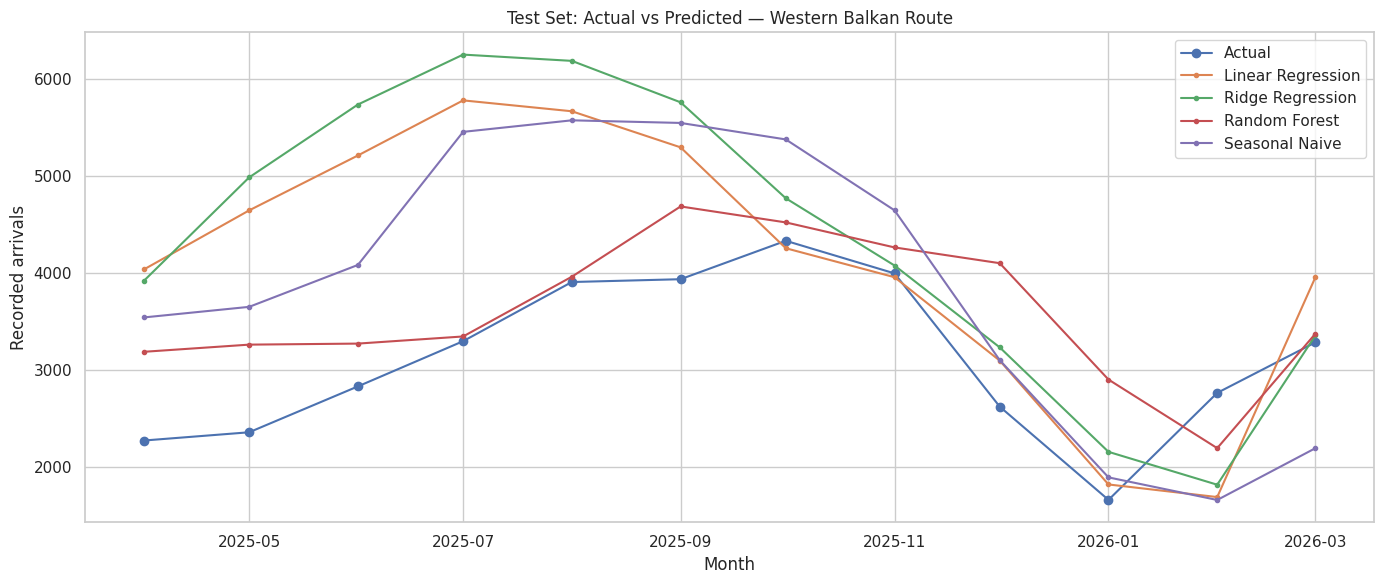

In [13]:
plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values, marker='o', label='Actual')

for name, pred in predictions.items():
    plt.plot(y_test.index, pred, marker='.', label=name)

plt.title(f'Test Set: Actual vs Predicted — {TARGET_NAME}')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Time-series cross-validation on the training data

I used expanding-window validation to assess whether the model is reasonably stable across several preceding test periods. The final test set, which covers 12 months, remains unchanged during this step.

In [20]:
tscv = TimeSeriesSplit(n_splits=3)

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_mean_absolute_error'
    )
    cv_rows.append({
        'Model': name,
        'Mean CV MAE': -scores.mean(),
        'Std CV MAE': scores.std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values('Mean CV MAE').round(2)
display(cv_results)

,Model,Mean CV MAE,Std CV MAE
1,Ridge Regression,3530.61,1161.23
2,Random Forest,3910.30,370.38
0,Linear Regression,4395.62,1371.05


## 13. Select a model and refit it on all observed data

I selected the model using both test set results and time series cross-validation. I didn't automatically choose "Random Forest": a simpler model or a seasonal baseline if my perform better.

In [15]:
# Set this after reviewing results:
BEST_MODEL_NAME = results.iloc[0]['Model']

if BEST_MODEL_NAME == 'Seasonal Naive':
    raise ValueError(
        'Seasonal Naive is a baseline, not an sklearn model for recursive forecasting. '
        'Choose a trained ML model for the recursive forecast, or report the baseline separately.'
    )

final_model = models[BEST_MODEL_NAME]
final_model.fit(X, y)

print('Selected ML model:', BEST_MODEL_NAME)

Selected ML model: Random Forest


## 14. Recursive forecast for the next 3, 6 and 12 months

This is a recursive forecast: each predicted month is fed into the model to create features for the next month. Errors can accumulate with the forecast horizon. The model uses historical patterns only; it does not know future policy changes, conflicts or other external events.

In [16]:
def recursive_forecast(history, fitted_model, feature_columns, horizon=6):
    values = list(history.astype(float).values)
    last_date = history.index[-1]
    future_dates = []
    forecast_values = []

    for step in range(1, horizon + 1):
        next_date = last_date + pd.DateOffset(months=step)

        next_features = pd.DataFrame([{
            'Time_Index': len(values),
            'Month_Sin': np.sin(2 * np.pi * next_date.month / 12),
            'Month_Cos': np.cos(2 * np.pi * next_date.month / 12),
            'Lag_1': values[-1],
            'Lag_3': values[-3],
            'Lag_6': values[-6],
            'Lag_12': values[-12],
            'Rolling_Mean_3': np.mean(values[-3:]),
            'Rolling_Mean_6': np.mean(values[-6:])
        }], columns=feature_columns)

        prediction = float(fitted_model.predict(next_features)[0])
        prediction = max(0, prediction)

        future_dates.append(next_date)
        forecast_values.append(prediction)
        values.append(prediction)

    return pd.Series(
        forecast_values,
        index=pd.DatetimeIndex(future_dates, name='Month'),
        name='Forecast'
    )

forecast_3 = recursive_forecast(target, final_model, FEATURES, horizon=3)
forecast_6 = recursive_forecast(target, final_model, FEATURES, horizon=6)
forecast_12 = recursive_forecast(target, final_model, FEATURES, horizon=12)

forecast_table = pd.concat([
    forecast_12.rename('Forecasted recorded arrivals')
], axis=1)

display(forecast_table.round(0))

,Forecasted recorded arrivals
Month,
2026-04-01,3598.0
2026-05-01,3744.0
2026-06-01,3900.0
2026-07-01,3897.0
2026-08-01,3875.0
2026-09-01,3875.0
2026-10-01,3839.0
2026-11-01,3707.0
2026-12-01,3451.0


## 15. Plot the 12-month forecast

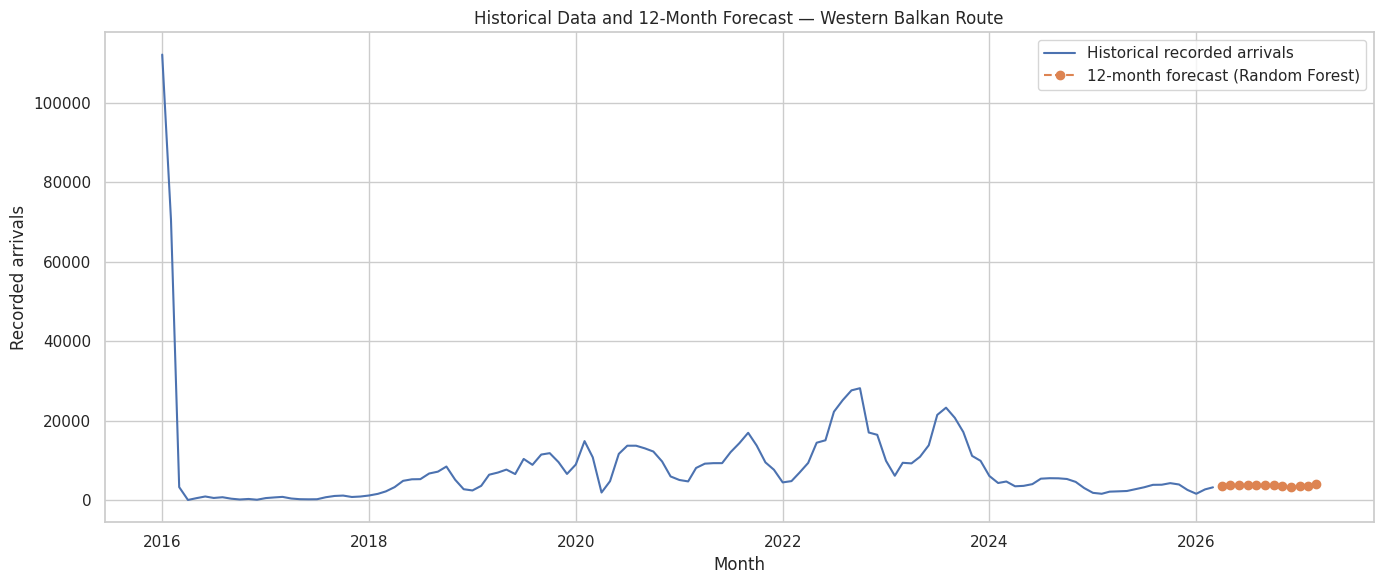

In [17]:
plt.figure(figsize=(14, 6))
plt.plot(target.index, target.values, label='Historical recorded arrivals')
plt.plot(
    forecast_12.index,
    forecast_12.values,
    marker='o',
    linestyle='--',
    label=f'12-month forecast ({BEST_MODEL_NAME})'
)
plt.title(f'Historical Data and 12-Month Forecast — {TARGET_NAME}')
plt.xlabel('Month')
plt.ylabel('Recorded arrivals')
plt.legend()
plt.tight_layout()
plt.show()

## 16. Forecast summary and interpretation

Report:
- the selected target (route-wide WBR or Montenegro WBR);
- the last observed month in the Q1 2026 source;
- the model selected and why;
- test MAE and RMSE;
- comparison with the seasonal-naive baseline;
- the 3-, 6- and 12-month estimates;
- limitations and uncertainty.
